In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '2'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [3]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from corner import corner, overplot_lines, overplot_points
from jax import jit
from scipy.stats import qmc
from scipy.stats import t as stuent_t
from raddest.reg.func import generate_piecewise_linear
from utils.linear_model import get_ODR, get_OLS, xy2logxy


In [4]:
n_piece = 3
b0 = 0.0
x0 = -0.4
k_lst = [0.5, 1.2, 0.5]
dx_lst = [0.8]
sig = 0.1
N = 10000

k_main = k_lst[1]
b_main = k_lst[0] * x0 + b0 - k_lst[1] * x0

piecewise_linear = generate_piecewise_linear(n_piece)

x = 10**np.random.normal(0, 0.3, size=N)

y = 10**(piecewise_linear(np.log10(x), b0, x0, k_lst, dx_lst) +
         np.random.normal(0, sig, size=N))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)

y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

Text(0, 0.5, 'log(y)')

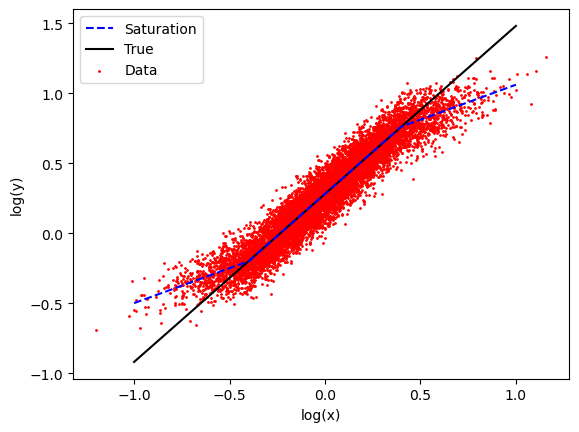

In [5]:
log_xx = np.linspace(-1, 1, 1000)
log_yy = k_main * log_xx + b_main
log_yy_sat = piecewise_linear(log_xx, b0, x0, k_lst, dx_lst)
plt.plot(log_xx,
         log_yy_sat,
         color='blue',
         label='Saturation',
         zorder=10,
         linestyle='--')
plt.plot(log_xx, log_yy, color='black', label='True')
plt.scatter(np.log10(x), np.log10(y), color='red', label='Data', s=1)
plt.legend()
plt.xlabel('log(x)')
plt.ylabel('log(y)')

In [6]:
logx_obs, logy_obs, logx_err, logy_err = xy2logxy(x_obs, y_obs, x_err, y_err)

/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:24: RuntimeWarning: invalid value encountered in log10
  logx = np.log10(x)
/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:25: RuntimeWarning: invalid value encountered in log10
  logy = np.log10(y)


In [7]:
res_ODR = get_ODR(logx_obs, logy_obs)
res_OLS = get_OLS(logx_obs, logy_obs)

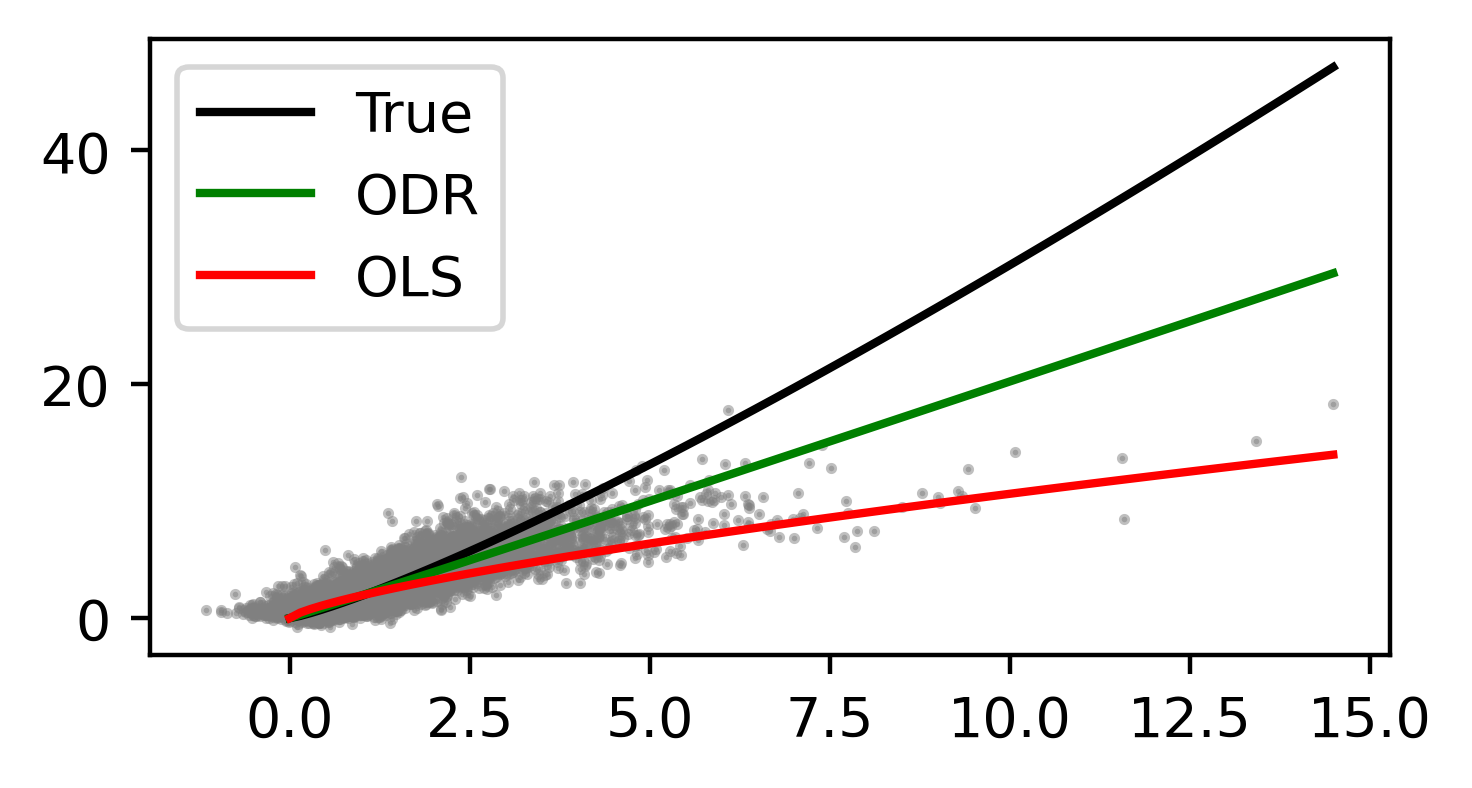

In [8]:
plt.figure(figsize=(4, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10**(k_main * np.log10(xx) + b_main)
# yy_sat = 10**linear_sigmoid(np.log10(xx), k, b, x0, x1, c0, c1)
yy_ODR = 10**res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10**res_OLS['func'](np.log10(xx))

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from jax.scipy.stats import norm

from raddest.api.fitter import (LogLinearKS, LogLinearML, LogLinearStudentTML)
from raddest.api.flowvi import FlowVI
from raddest.reg.map import get_w_add_lognorm
from raddest.transfer import NegLogPlus

In [10]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=NegLogPlus())

xflow.fit(x_obs, x_err, verbose=True)

100%|██████████| 100/100 [00:08<00:00, 12.11it/s]


step 0: loss 0.38350406289100647
step 10: loss 0.3250802159309387
step 20: loss 0.3183795213699341
step 30: loss 0.31704214215278625
step 40: loss 0.3128054141998291
step 50: loss 0.3097170293331146
step 60: loss 0.30879107117652893
step 70: loss 0.30741631984710693


In [11]:
xflow.ks_test(x_obs, x_err, 10000)

(0.01145001407712698, 0.7869556525602467)

In [12]:
yflow = FlowVI(x_min=0,
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2,
               transfer=NegLogPlus())

yflow.fit(y_obs, y_err, verbose=True)

100%|██████████| 100/100 [00:07<00:00, 12.69it/s]


step 0: loss 1.0807263851165771
step 10: loss 0.9912335872650146
step 20: loss 0.9748615026473999
step 30: loss 0.9716119170188904
step 40: loss 0.9681933522224426
step 50: loss 0.9659355282783508
step 60: loss 0.963543713092804
step 70: loss 0.9626109004020691


In [13]:
yflow.ks_test(y_obs, y_err, 10000)

(0.017000027000904083, 0.30367301303233823)

### Normal Model

In [ ]:
loglinear_ML = LogLinearML(xflow, yflow)

In [ ]:
params_ml, params_std, cov = loglinear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    [1., 0., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0030255 0.012616883 0.12505141 -0.6959337
1000 1.0351622 0.28597096 0.114417285 0.52916336
2000 1.0353189 0.28594622 0.11441355 0.52916336
converged, so stop with 2000 iterations


In [39]:
print('ML fitted:', *params_ml)
print('Truth:', k_main, b_main, sig)

ML fitted: 1.0353189 0.28594622 0.11441355
Truth: 1.2 0.27999999999999997 0.1


### T Model

In [ ]:
logLinear_studentT_ML = LogLinearStudentTML(xflow, yflow)

In [ ]:
params_ml_t, params_std_t, cov_t = logLinear_studentT_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    [1., 0., 2., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0006961 0.0052003823 1.9999148 0.10557076 -0.3980544
1000 1.0488334 0.2881962 2.0255263 0.069098614 0.50001764
2000 1.0503345 0.28790072 2.048082 0.06942855 0.5005302
3000 1.0503731 0.28785667 2.0700336 0.069789365 0.5010124
4000 1.0502539 0.2878419 2.0914416 0.0701408 0.5014699
5000 1.0501347 0.2878284 2.112329 0.070478775 0.5019073
6000 1.0500154 0.2878161 2.132719 0.07080404 0.5023229
7000 1.0498962 0.28780496 2.152637 0.07111746 0.5027197
8000 1.049777 0.2877949 2.1721106 0.07141984 0.5030977
9000 1.0496578 0.28778577 2.1911702 0.07171204 0.5034619
10000 1.0495538 0.28777516 2.2098472 0.071994275 0.5038112
11000 1.0494545 0.2877647 2.228113 0.07226676 0.50414467
12000 1.0493585 0.2877545 2.2460446 0.07253106 0.5044666
13000 1.0492661 0.28774455 2.2636018 0.07278667 0.50477487
14000 1.0491766 0.28773484 2.2808537 0.07303486 0.505073
15000 1.0490901 0.28772536 2.2977755 0.07327558 0.5053591
16000 1.0490063 0.28771612 2.314385 0.0735092 0.505635
17000 1.0489253 0.28770706 2.330713

In [42]:
print('ML fitted:', *params_ml_t)
print('Truth:', k_main, b_main, sig)

ML fitted: 1.044502 0.28709853 3.7754295 0.08720835
Truth: 1.2 0.27999999999999997 0.1


In [43]:
q_16, q_84 = stuent_t.ppf([0.16, 0.84],
                          float(params_ml_t[-2]),
                          scale=float(params_ml_t[-1]))
(q_84 - q_16) / 2

0.09975050163641067

### KS

In [ ]:
logLinear_KS = LogLinearKS(xflow, yflow)

In [ ]:
params_mean, params_std, res_arr = logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

----
k: 1.144 +/- 0.074
b: 0.299 +/- 0.010
sig: 0.124 +/- 0.033
----
k: 1.187 +/- 0.079
b: 0.277 +/- 0.010
sig: 0.080 +/- 0.058
----
k: 1.183 +/- 0.078
b: 0.283 +/- 0.022
sig: 0.087 +/- 0.057
----
k: 1.183 +/- 0.088
b: 0.277 +/- 0.021
sig: 0.094 +/- 0.061
----
k: 1.176 +/- 0.088
b: 0.285 +/- 0.021
sig: 0.090 +/- 0.059
----
k: 1.195 +/- 0.080
b: 0.274 +/- 0.020
sig: 0.093 +/- 0.059
----
k: 1.167 +/- 0.079
b: 0.288 +/- 0.018
sig: 0.088 +/- 0.056
----
k: 1.202 +/- 0.084
b: 0.273 +/- 0.017
sig: 0.087 +/- 0.059
----
k: 1.170 +/- 0.080
b: 0.287 +/- 0.018
sig: 0.094 +/- 0.058
----
k: 1.188 +/- 0.082
b: 0.273 +/- 0.018
sig: 0.095 +/- 0.059
----
k: 1.157 +/- 0.083
b: 0.287 +/- 0.018
sig: 0.092 +/- 0.055
max iteration reached
[1.18042946 0.28047733 0.0897785 ] [0.08050585 0.01498273 0.0556563 ]


In [16]:
print('KS fitted:', *params_mean)
print('Truth:', k_main, b_main, sig)

KS fitted: 1.1804294622640115 0.280477327618672 0.08977849563190518
Truth: 1.2 0.27999999999999997 0.1


### Piecewise Log-Linear ML

In [ ]:
from raddest.api.fitter import PiecewiseLogLinearML

In [ ]:
piecewise_loglinear = PiecewiseLogLinearML(xflow, yflow, 3, width=0.1)

In [ ]:
q5 = np.log10(np.percentile(x_obs, 5))
q95 = np.log10(np.percentile(x_obs, 95))
params0 = [0., q5] + [1., 1., 1.] + [q95 - q5] + [0.2]
# params0 = (b0, x0) + k_lst + dx_lst + sig

params_ml_piecewise, params_std_piecewise, cov_piecewise = piecewise_loglinear.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    params0,
    ignore_y_err_c_y=True,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 0.0045340876 -0.86066717 0.9960998 1.00458 0.99997616 1.3636848 0.20391831 -1.0562595
1000 0.11165121 -0.9028521 0.9038246 1.0910107 0.93828005 1.3328735 0.11087838 -0.40460408
2000 0.103027865 -0.9333291 0.9120154 1.1042414 0.8703646 1.3008996 0.107849926 -0.39765766
3000 0.09190458 -0.94632286 0.92275053 1.124627 0.8147704 1.2859527 0.105742104 -0.39343828
4000 0.083877884 -0.9470143 0.9306519 1.1401303 0.7723005 1.2839255 0.10444864 -0.3912376
5000 0.0794482 -0.9442777 0.9351685 1.1491002 0.7381387 1.2860901 0.10360958 -0.3899289
6000 0.07743556 -0.94095856 0.93741596 1.1536157 0.7097217 1.2893752 0.10305174 -0.38906628
7000 0.0768223 -0.93772453 0.9383566 1.1555291 0.68564475 1.2928611 0.10267134 -0.3884572
8000 0.076968335 -0.9347718 0.93859684 1.156006 0.6649652 1.2962565 0.102404684 -0.38800806
9000 0.077495776 -0.93215245 0.9384776 1.1557301 0.6470115 1.2993947 0.10221307 -0.387668
10000 0.078205414 -0.9298589 0.9382105 1.1550906 0.63129354 1.302253 0.10207185 -0.3874061
1100

In [ ]:
piecewise_loglinear.ks_test(params_ml_piecewise, x_obs, y_obs)

(0.01219999697059393, 0.6019605235689076)

In [36]:
print('Ouecewise ML fitted:', *params_ml_piecewise)
print('Truth:', [0.0, -0.4, 0.5, 1.2, 0.5, 0.8, 0.1])

Ouecewise ML fitted: 0.0891242 -0.9156893 0.9378944 1.1454625 0.5049226 1.3276569 0.10154534
Truth: [0.0, -0.4, 0.5, 1.2, 0.5, 0.8, 0.1]


In [ ]:
# as can be seen, the first piece is hard to be constrained. Because the noise is relatively large in small x end.

print('Piecewise ML fitted (k_lst, b_lst, x_lst, sig):',
      *piecewise_loglinear.to_each_piece_params(params_ml_piecewise))
print(
    'Truth (k_lst, b_lst, x_lst, sig):',
    *piecewise_loglinear.to_each_piece_params(
        [0.0, -0.4, 0.5, 1.2, 0.5, 0.8, 0.1]))

Piecewise ML fitted (k_lst, b_lst, x_lst, sig): [0.9378944 1.1454625 0.5049226] [0.0891242 0.2791921 0.5430738] [-0.9156893   0.41196758] 0.10154534131288528
Truth (k_lst, b_lst, x_lst, sig): [0.5 1.2 0.5] [0.   0.28 0.56] [-0.4  0.4] 0.1


In [ ]:
piecewise_loglinear_regressor_fixed = PiecewiseLogLinearML(
    xflow,
    yflow,
    3,
    width=0.1,
    is_fixed=[False, False, False, True, False, False, False])

params0 = [0., q5] + [1., 1.18, 1.] + [q95 - q5] + [0.2]

params_ml_piecewise_fixed, params_std_piecewise_fixed, cov_piecewise_fixed = piecewise_loglinear_regressor_fixed.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    params0,
    ignore_y_err_c_y=True,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 0.0015952664 -0.8609675 0.9986286 1.18 0.99997705 1.3636734 0.19920583 -0.583596
1000 0.05572958 -0.9468609 0.9524498 1.18 0.9174846 1.2895819 0.10761176 -0.40273055
2000 0.05662613 -0.97752005 0.95192206 1.18 0.84397084 1.2596223 0.10494262 -0.39457312
3000 0.057810836 -0.97229993 0.9510876 1.18 0.79897624 1.2655708 0.104011714 -0.3924466
4000 0.058627393 -0.9645099 0.95063186 1.18 0.76316 1.2740147 0.103281476 -0.39102682
5000 0.05927256 -0.95841825 0.95035994 1.18 0.7327744 1.280736 0.102736056 -0.3900181
6000 0.059809092 -0.9537136 0.95021075 1.18 0.7067997 1.2860537 0.10232583 -0.38929087
7000 0.060265597 -0.9499944 0.9501472 1.18 0.6844933 1.2903742 0.10201234 -0.38875958
8000 0.060666222 -0.9470008 0.9501484 1.18 0.6652479 1.2939631 0.10176909 -0.3883664
9000 0.061027862 -0.94456035 0.95020133 1.18 0.64856935 1.2969905 0.10157778 -0.38807246
10000 0.061352216 -0.94255024 0.9502863 1.18 0.63405704 1.2995782 0.10142577 -0.38785064
11000 0.06165618 -0.9408866 0.9504053 1.18 0.621

In [ ]:
print(
    'Piecewise ML fitted, k1 fixed (k_lst, b_lst, x_lst, sig):',
    *piecewise_loglinear_regressor_fixed.to_each_piece_params(
        params_ml_piecewise_fixed))
print(
    'Truth (k_lst, b_lst, x_lst, sig):',
    *piecewise_loglinear_regressor_fixed.to_each_piece_params(
        [0.0, -0.4, 0.5, 1.2, 0.5, 0.8, 0.1]))

Piecewise ML fitted, k1 fixed (k_lst, b_lst, x_lst, sig): [0.95427763 1.18       0.5356112 ] [0.06557837 0.27636826 0.5245281 ] [-0.93384606  0.3851089 ] 0.1007145568728447
Truth (k_lst, b_lst, x_lst, sig): [0.5 1.2 0.5] [0.   0.28 0.56] [-0.4  0.4] 0.1


In [ ]:
initial_state = np.random.uniform(low=[-0.2, -1, 0, 0, 0, 0.5, 0.02],
                                  high=[0.2, 0, 2, 2, 2, 1, 0.3],
                                  size=(28, 7))

In [ ]:
sampler = piecewise_loglinear.get_posterior_mcmc(
    x_obs,
    x_err,
    y_obs,
    y_err,
    ndim=7,
    nsteps=30000,
    initial_state=initial_state,
    ignore_y_err_c_y=True,
    run_mcmc_kwargs={'progress': True})

100%|██████████| 30000/30000 [03:36<00:00, 138.70it/s]


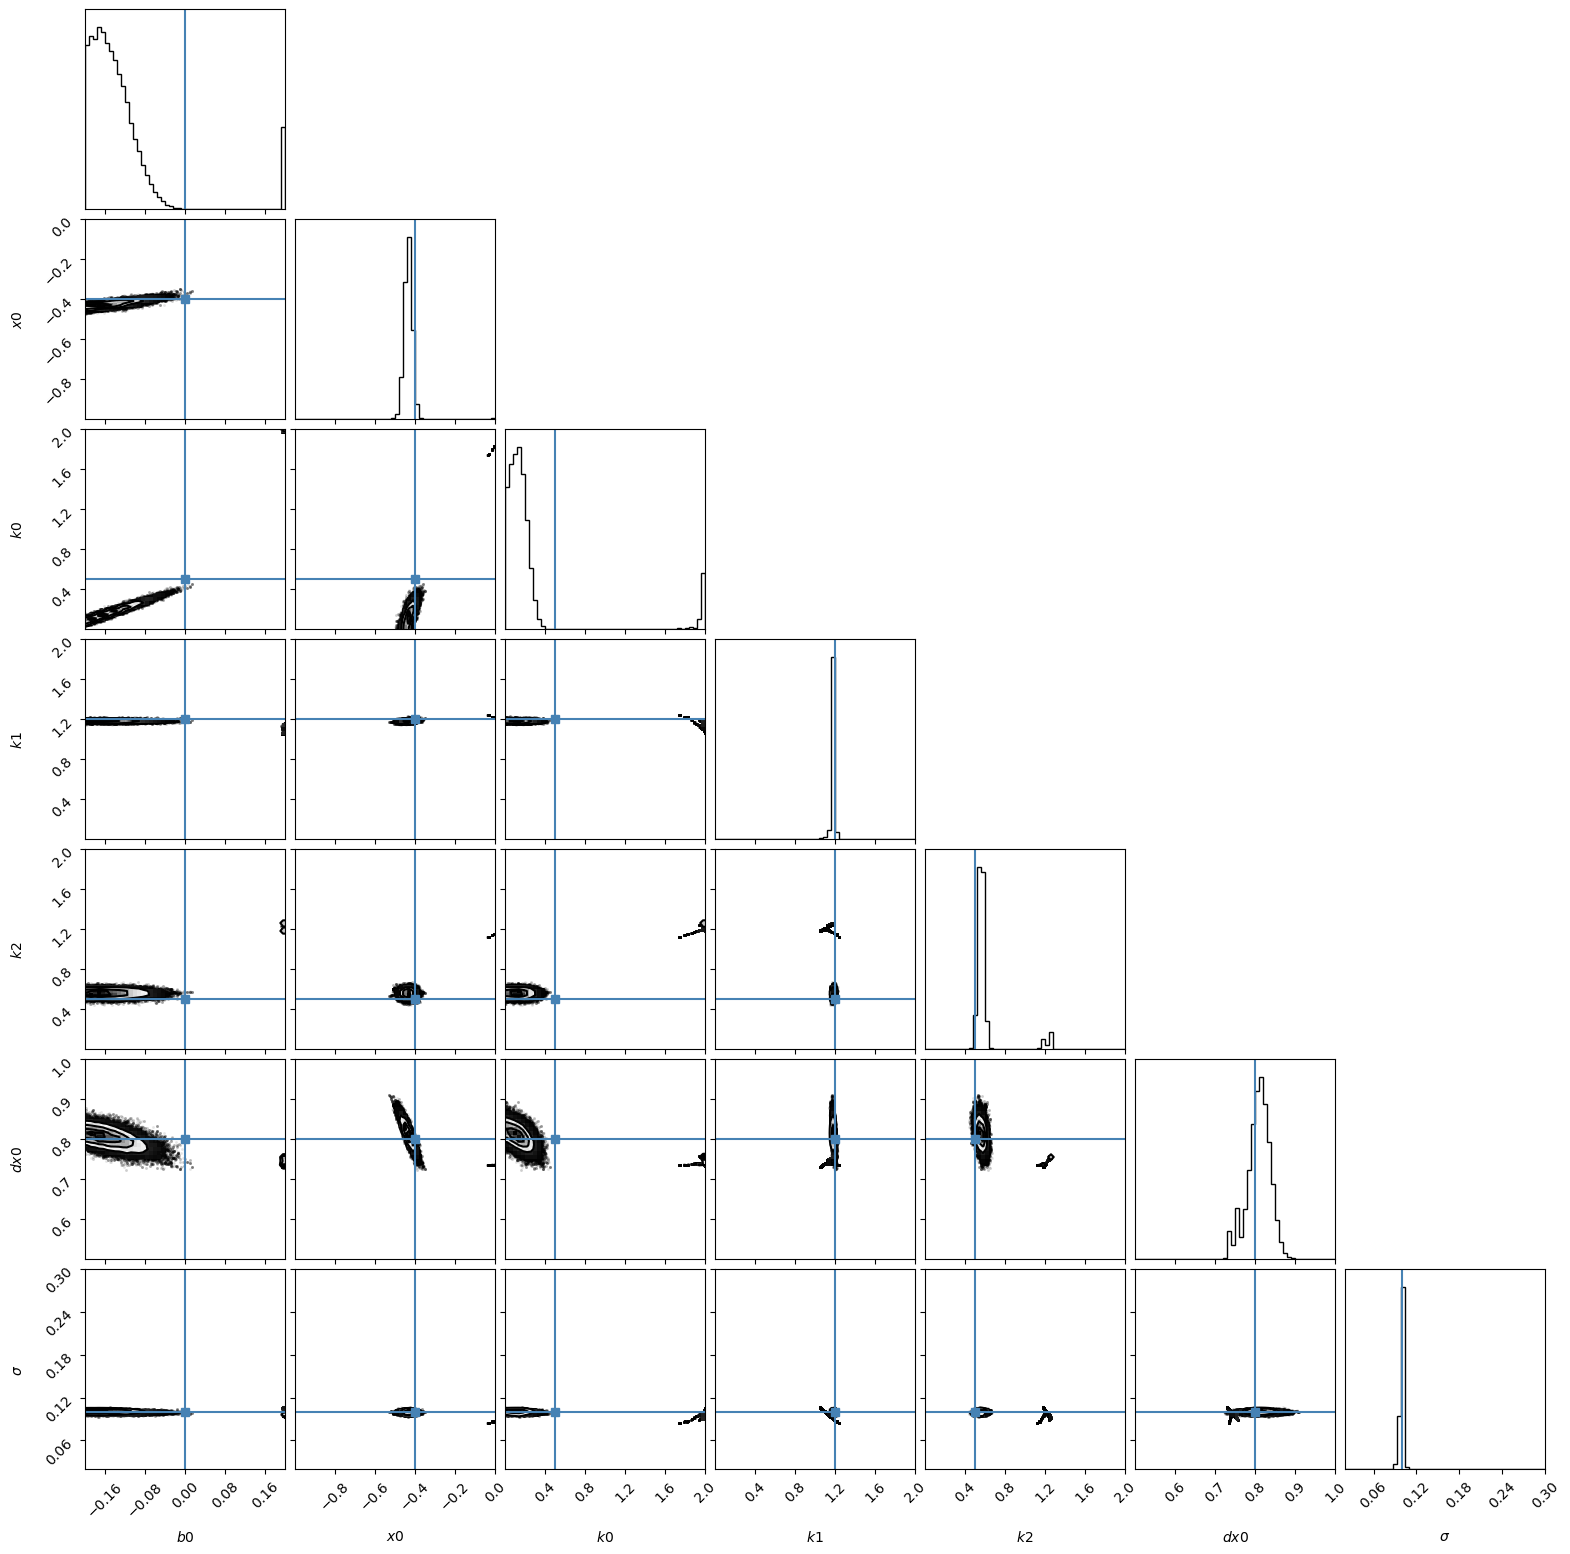

In [142]:
fig = corner(
    sampler.get_chain(flat=True, discard=20000),
    truths=[0.0, -0.4, 0.5, 1.2, 0.5, 0.8, 0.1],
    # truths=params_ml_piecewise,
    labels=["$b0$", "$x0$", "$k0$", "$k1$", "$k2$", "$dx0$", "$\sigma$"],
    range=[(-0.2, 0.2), (-1, 0), (0, 2), (0, 2), (0, 2), (0.5, 1), (0.02, 0.3)],
    bins=50,
    # plot_datapoints=False,
    plot_density=True,
)

## Compare

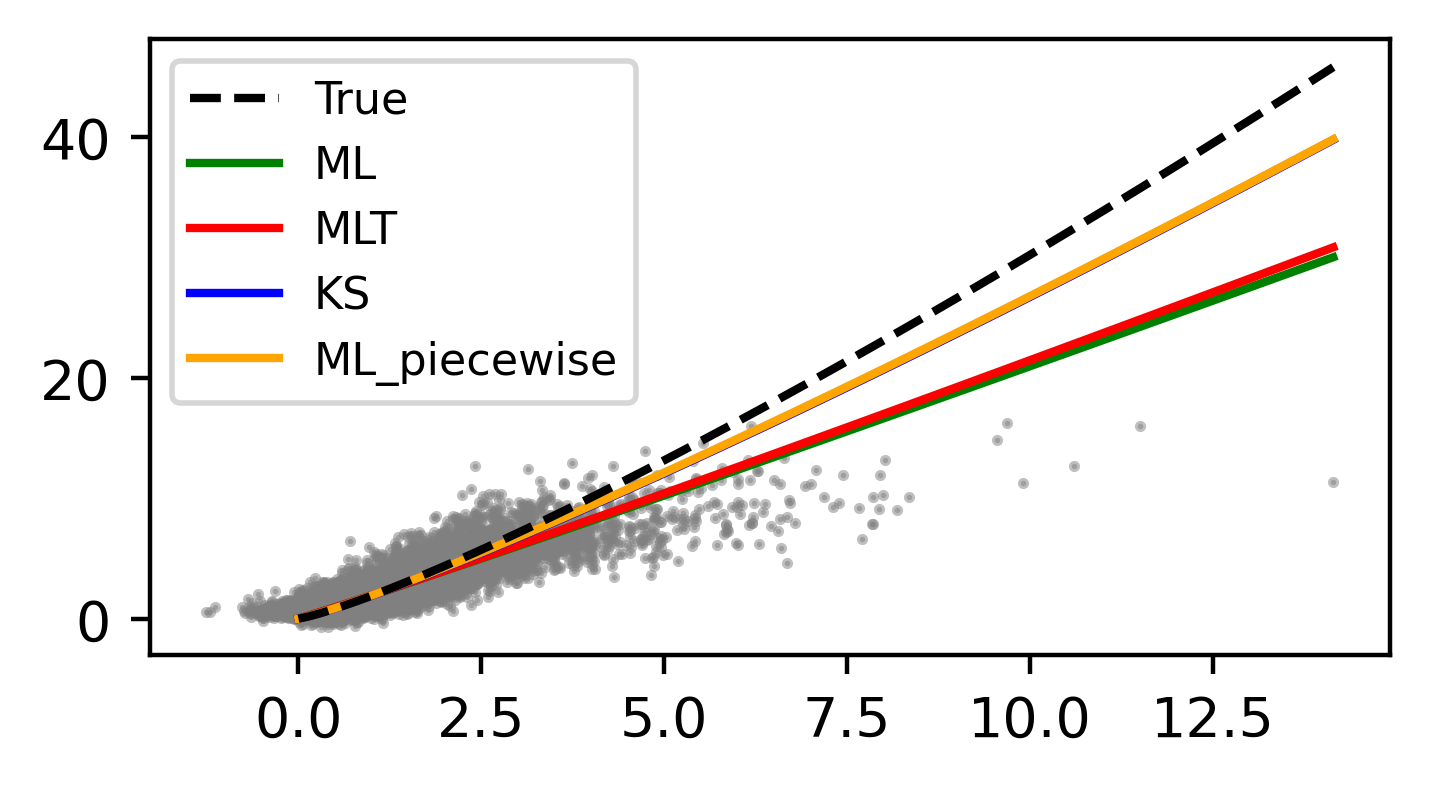

In [158]:
plt.figure(figsize=(4, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10**(k_main * np.log10(xx) + b_main)
yy_ML = 10**(params_ml[0] * np.log10(xx) + params_ml[1])
yy_MLT = 10**(params_ml_t[0] * np.log10(xx) + params_ml_t[1])
yy_KS = 10**(params_mean[0] * np.log10(xx) + params_mean[1])
# yy_ML_saturated = 10**saturated_linear_smooth(np.log10(xx),
#                                               *params_ml_saturated_c[:-1])
yy_ML_saturated = 10**(params_ml_piecewise[3] * np.log10(xx) +
                       params_ml_piecewise[0] +
                       params_ml_piecewise[2] * params_ml_piecewise[1] -
                       params_ml_piecewise[3] * params_ml_piecewise[1])

plt.plot(xx, yy, color='black', label='True', zorder=10, linestyle='--')
plt.plot(xx, yy_ML, color='green', label='ML')
plt.plot(xx, yy_MLT, color='red', label='MLT')
plt.plot(xx, yy_KS, color='blue', label='KS')
plt.plot(xx, yy_ML_saturated, color='orange', label='ML_piecewise')

plt.legend(fontsize=8)